# Setup Test

Pertanyaan yang ingin dijawab notebook ini: **seberapa layak environment ini dijalankan, dan di mesin seperti apa?**

Yang diukur adalah proses menyiapkan database, bukan kecepatan query. Prosesnya sama untuk tiga ukuran data:
- **small:** 10 ribu order
- **medium:** 100 ribu order
- **large:** 1 juta order

Untuk setiap ukuran, `scripts/measure_setup.py` membuat database sementara di container PostgreSQL, lalu menjalankan tiga tahap berurutan:
1. **Skema:** menjalankan DDL (tabel, constraint, indeks, function, trigger) dalam satu transaksi.
2. **Pembangkitan data:** `generate_data.py` menulis seluruh data sintetis menjadi satu script SQL (perintah `COPY`).
3. **Pengisian data:** script SQL itu dimuat ke PostgreSQL dalam satu transaksi.

Selama proses, memori dan CPU container dibaca dari cgroup setiap sekitar 0,2 detik, sedangkan ukuran database, tabel, indeks, dan WAL dibaca dari PostgreSQL setelah pengisian selesai. Database sementara dihapus setelah pengukuran, jadi database utama tidak tersentuh.

Analisisnya disusun dari environment ke hasil:
- **Bagian 1:** spesifikasi mesin dan konfigurasi PostgreSQL yang dipakai.
- **Bagian 2:** waktu pembuatan skema.
- **Bagian 3:** waktu pembangkitan dan pengisian data, serta bagaimana waktunya tumbuh.
- **Bagian 4:** pemakaian memori dan CPU.
- **Bagian 5:** pemakaian storage (database, tabel, indeks, WAL).
- **Bagian 6:** kelayakan: mesin seperti apa yang cukup untuk setiap ukuran data.
- **Bagian 7:** kesimpulan.

Semua angka di notebook ini berasal dari file `setup_*.json` di `results/`. Satuan ukuran memakai kelipatan 1024 (KiB, MiB, GiB).

In [1]:
import json
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from IPython.display import Markdown, display
from matplotlib.ticker import FuncFormatter

ROOT = Path.cwd().parent if Path.cwd().name == 'notebook' else Path.cwd()
RESULTS = ROOT / 'results'
PROFILES = ['small', 'medium', 'large']


def latest(pattern: str) -> Path:
    files = sorted(RESULTS.glob(pattern))
    if not files:
        raise FileNotFoundError(f'Tidak ada file {pattern} di {RESULTS}')
    return files[-1]


config = yaml.safe_load((ROOT / 'config' / 'dataset_profile.yaml').read_text())
ORDERS = {p: config['profiles'][p]['service_orders'] for p in PROFILES}
DIST = config['order_distribution']

S, FILES = {}, {}
for profile in PROFILES:
    path = latest(f'setup_{profile}_*.json')
    FILES[profile] = path.name
    S[profile] = json.loads(path.read_text())
    assert S[profile]['profile'] == profile

# Satu pengukuran per ukuran data, dengan mesin, image, dan konfigurasi yang sama.
for key in ('postgres_version', 'postgres_settings', 'host', 'docker'):
    assert all(S[p][key] == S['small'][key] for p in PROFILES), f'{key} berbeda antar ukuran data'
HOST, DOCKER, SETTINGS = S['small']['host'], S['small']['docker'], S['small']['postgres_settings']

pd.DataFrame({
    'ukuran data': PROFILES,
    'service orders': [f'{ORDERS[p]:,}' for p in PROFILES],
    'file hasil': [FILES[p] for p in PROFILES],
    'PostgreSQL': [S[p]['postgres_version'].split()[0] for p in PROFILES],
    'diukur (UTC)': [S[p]['measured_at'] for p in PROFILES],
})

,ukuran data,service orders,file hasil,PostgreSQL,diukur (UTC)
0,small,"10,000",setup_small_20261104-200853.json,17.11,2026-11-04T13:08:53+00:00
1,medium,"100,000",setup_medium_20261104-200920.json,17.11,2026-11-04T13:09:19+00:00
2,large,"1,000,000",setup_large_20261104-201311.json,17.11,2026-11-04T13:13:10+00:00


In [2]:
INK, INK_2, MUTED = '#0b0b0b', '#52514e', '#898781'
SURFACE, GRID, AXIS = '#fcfcfb', '#e1e0d9', '#c3c2b7'
BLUE, ORANGE = '#2a78d6', '#eb6834'
PROFILE_COLORS = {'small': '#86b6ef', 'medium': '#2a78d6', 'large': '#104281'}

plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'figure.dpi': 110, 'font.family': 'sans-serif', 'font.size': 10,
    'text.color': INK, 'axes.labelcolor': INK_2, 'axes.titlecolor': INK,
    'axes.titlesize': 11, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.edgecolor': AXIS, 'axes.linewidth': 0.8, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6, 'grid.linestyle': '-',
    'xtick.color': MUTED, 'ytick.color': MUTED, 'xtick.labelcolor': INK_2, 'ytick.labelcolor': INK_2,
    'legend.frameon': False, 'legend.fontsize': 9,
})
PLAIN = FuncFormatter(lambda v, _: f'{v:,.0f}' if v >= 1 else f'{v:g}')

In [3]:
def dec(value, digits=1):
    return f'{value:.{digits}f}'.replace('.', ',')


def count_id(n):
    return f'{int(n):,}'.replace(',', '.')


def pct_id(value, digits=1):
    return dec(value, digits) + '%'


def size_text(n, digits=1):
    if n >= 2 ** 30:
        return dec(n / 2 ** 30, 2) + ' GiB'
    if n >= 2 ** 20:
        return dec(n / 2 ** 20, digits) + ' MiB'
    return dec(n / 2 ** 10, digits) + ' KiB'


def sec_text(s):
    if s >= 60:
        minutes = int(s // 60)
        return f'{minutes} menit {round(s - 60 * minutes)} detik'
    if s >= 10:
        return dec(s) + ' detik'
    return dec(s, 2) + ' detik'


def times(x):
    return dec(x) + '×'


def names(items):
    items = [str(i) for i in items]
    return items[0] if len(items) == 1 else ', '.join(items[:-1]) + ' dan ' + items[-1]


def md_table(frame):
    head = '| ' + ' | '.join(str(c) for c in frame.columns) + ' |'
    rule = '|' + '|'.join('---' for _ in frame.columns) + '|'
    body = ['| ' + ' | '.join(str(v) for v in row) + ' |' for row in frame.itertuples(index=False)]
    return '\n'.join([head, rule, *body])


def say(text):
    display(Markdown(text))


def show(frame):
    say(md_table(frame))


def loglog_slope(values):
    # Eksponen b pada model nilai ∝ (jumlah order)^b, dari tiga ukuran data.
    return np.polyfit([math.log10(ORDERS[p]) for p in PROFILES], [math.log10(v) for v in values], 1)[0]


def growth(values):
    # Kenaikan saat data naik 10 kali: small ke medium, lalu medium ke large.
    return [values[1] / values[0], values[2] / values[1]]

## 1. Environment pengujian

Hasil setup bergantung pada mesin yang menjalankannya, jadi spesifikasinya dicatat lebih dulu. Ketiga ukuran data diukur di mesin, image, dan konfigurasi PostgreSQL yang sama (notebook ini memeriksanya), sehingga perbedaan hasil murni berasal dari ukuran data.

In [4]:
env = [
    ('Host', 'Sistem operasi', HOST['platform']),
    ('Host', 'CPU', f"{HOST['cpu']} ({HOST['cpu_count']} core)"),
    ('Host', 'Memori (RAM)', size_text(HOST['memory_bytes'])),
    ('Host', 'Disk', size_text(HOST['disk_bytes'])),
    ('Docker', 'Versi', f"{DOCKER['os']} {DOCKER['version']}, kernel {DOCKER['kernel']}"),
    ('Docker', 'CPU yang dialokasikan', f"{DOCKER['cpus']} core"),
    ('Docker', 'Memori yang dialokasikan', size_text(DOCKER['memory_bytes'])),
    ('Docker', 'Image', f"{DOCKER['image']} ({size_text(DOCKER['image_bytes'])})"),
    ('PostgreSQL', 'Versi', S['small']['postgres_version']),
    *[('PostgreSQL', name, value) for name, value in SETTINGS.items()],
]
show(pd.DataFrame(env, columns=['kelompok', 'komponen', 'nilai']))

mem_share = DOCKER['memory_bytes'] / HOST['memory_bytes']
say(f"""
**Cara membaca:**
- Docker Desktop menjalankan container di dalam mesin virtual. Dari {size_text(HOST['memory_bytes'])} RAM host, hanya {size_text(DOCKER['memory_bytes'])} ({pct_id(mem_share * 100, 0)}) yang tersedia untuk container, dan angka inilah batas memori yang sebenarnya dihadapi PostgreSQL.
- Konfigurasi PostgreSQL adalah bawaan image (`shared_buffers` {SETTINGS['shared_buffers']}, `work_mem` {SETTINGS['work_mem']}, `max_wal_size` {SETTINGS['max_wal_size']}) dan tidak disetel ulang. Hasil di bawah menunjukkan apa yang terjadi kalau memakai pengaturan bawaan.
- Hanya ada satu pengukuran per ukuran data, tanpa pengulangan. Angka di bawah menunjukkan gambaran umum, bukan rata-rata yang punya simpangan baku. Selisih kecil (beberapa persen) antar-ukuran tidak boleh ditafsirkan berlebihan.
""")

| kelompok | komponen | nilai |
|---|---|---|
| Host | Sistem operasi | macOS-26.5.2-arm64-arm-64bit-Mach-O |
| Host | CPU | Apple M5 (10 core) |
| Host | Memori (RAM) | 16,00 GiB |
| Host | Disk | 926,30 GiB |
| Docker | Versi | Docker Desktop 29.5.3, kernel 6.12.76-linuxkit |
| Docker | CPU yang dialokasikan | 10 core |
| Docker | Memori yang dialokasikan | 7,75 GiB |
| Docker | Image | postgres:17 (152,6 MiB) |
| PostgreSQL | Versi | 17.11 (Debian 17.11-1.pgdg13+2) |
| PostgreSQL | effective_cache_size | 4GB |
| PostgreSQL | maintenance_work_mem | 64MB |
| PostgreSQL | max_connections | 100 |
| PostgreSQL | max_wal_size | 1GB |
| PostgreSQL | shared_buffers | 128MB |
| PostgreSQL | work_mem | 4MB |


**Cara membaca:**
- Docker Desktop menjalankan container di dalam mesin virtual. Dari 16,00 GiB RAM host, hanya 7,75 GiB (48%) yang tersedia untuk container, dan angka inilah batas memori yang sebenarnya dihadapi PostgreSQL.
- Konfigurasi PostgreSQL adalah bawaan image (`shared_buffers` 128MB, `work_mem` 4MB, `max_wal_size` 1GB) dan tidak disetel ulang. Hasil di bawah menunjukkan apa yang terjadi kalau memakai pengaturan bawaan.
- Hanya ada satu pengukuran per ukuran data, tanpa pengulangan. Angka di bawah menunjukkan gambaran umum, bukan rata-rata yang punya simpangan baku. Selisih kecil (beberapa persen) antar-ukuran tidak boleh ditafsirkan berlebihan.


## 2. Pembuatan skema

DDL dijalankan dalam satu transaksi, sebelum ada data. Bagian ini menjawab: seberapa berat membuat strukturnya saja?

In [5]:
objects = S['small']['schema']['objects']
assert all(S[p]['schema']['objects'] == objects for p in PROFILES)
schema_secs = [S[p]['schema']['seconds'] for p in PROFILES]

show(pd.DataFrame({
    'objek': [k.replace('_', ' ') for k in objects],
    'jumlah': list(objects.values()),
}))
show(pd.DataFrame({
    'ukuran data': PROFILES,
    'waktu skema': [dec(s, 3) + ' detik' for s in schema_secs],
}))

say(f"""
**Analisis:**
- Skema terdiri dari {objects['tables']} tabel, {objects['primary_keys']} primary key, {objects['foreign_keys']} foreign key, {objects['unique_constraints']} unique constraint, {objects['check_constraints']} check constraint, {objects['indexes']} indeks, {objects['functions']} function, dan {objects['triggers']} trigger. Jumlahnya sama di ketiga ukuran data karena skema tidak bergantung pada data.
- Waktu membuatnya {dec(min(schema_secs), 2)}–{dec(max(schema_secs), 2)} detik. Ini bukan bagian yang berat. Selisih antar-ukuran hanya variasi pengukuran, karena tabelnya masih kosong saat itu.
- Seluruh beban setup ada di tahap data (bagian 3).
""")

| objek | jumlah |
|---|---|
| tables | 13 |
| enum types | 11 |
| domains | 1 |
| primary keys | 13 |
| foreign keys | 14 |
| unique constraints | 7 |
| check constraints | 13 |
| indexes | 34 |
| functions | 7 |
| triggers | 21 |

| ukuran data | waktu skema |
|---|---|
| small | 0,207 detik |
| medium | 0,168 detik |
| large | 0,313 detik |


**Analisis:**
- Skema terdiri dari 13 tabel, 13 primary key, 14 foreign key, 7 unique constraint, 13 check constraint, 34 indeks, 7 function, dan 21 trigger. Jumlahnya sama di ketiga ukuran data karena skema tidak bergantung pada data.
- Waktu membuatnya 0,17–0,31 detik. Ini bukan bagian yang berat. Selisih antar-ukuran hanya variasi pengukuran, karena tabelnya masih kosong saat itu.
- Seluruh beban setup ada di tahap data (bagian 3).


## 3. Pembangkitan dan pengisian data

Dua tahap ini dipisah karena sifatnya berbeda:
- **Pembangkitan** berjalan di Python di luar database (membuat data sintetis dengan Faker dan menuliskannya sebagai script SQL).
- **Pengisian** berjalan di PostgreSQL (`COPY` dalam satu transaksi). Semua constraint, indeks, dan trigger sudah aktif selama pengisian, jadi biayanya ikut terhitung.

**Kepekaan terhadap ukuran data** dibaca dari dua angka, sama seperti di volume test:
- **Kenaikan:** nilai baru dibagi nilai sebelumnya saat data naik 10 kali (small ke medium, lalu medium ke large). Kalau pertumbuhannya linier, kenaikannya sekitar 10×.
- **Eksponen b:** pada model nilai ∝ (jumlah order)ᵇ, dari regresi log-log atas tiga ukuran data. b mendekati 1 berarti linier, di bawah 1 berarti lebih lambat dari pertumbuhan data, di atas 1 berarti lebih cepat. Karena hanya ada tiga titik, b tidak diberi interval kepercayaan dan dibaca sebagai gambaran kasar.

| ukuran data | baris total | baris per order | pembangkitan | pengisian | total | baris/detik (pengisian) |
|---|---|---|---|---|---|---|
| small | 60.350 | 6,04 | 0,45 detik | 1,88 detik | 2,33 detik | 32.186 |
| medium | 602.615 | 6,03 | 3,94 detik | 16,6 detik | 20,6 detik | 36.247 |
| large | 6.021.440 | 6,02 | 40,9 detik | 3 menit 5 detik | 3 menit 46 detik | 32.624 |

| tahap | small → medium | medium → large | eksponen b |
|---|---|---|---|
| pembangkitan | 8,7× | 10,4× | 0,98 |
| pengisian | 8,9× | 11,1× | 1,00 |
| total | 8,8× | 11,0× | 0,99 |

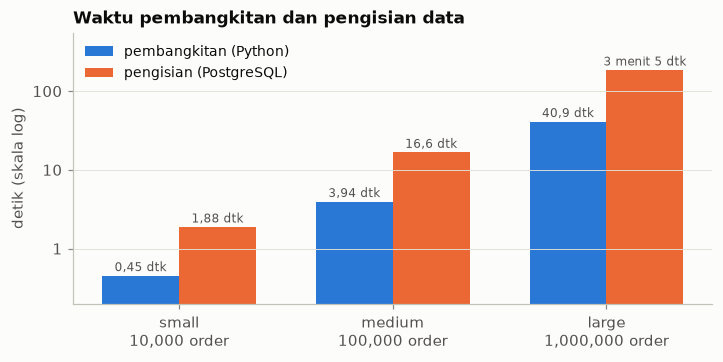


**Analisis:**
- **Total waktu:** 2,33 detik untuk small, 20,6 detik untuk medium, dan 3 menit 46 detik untuk large.
- **Pertumbuhan:** data naik 10 kali, tetapi pembangkitan naik 8,7× lalu 10,4× (b = 0,98), dan pengisian naik 8,9× lalu 11,1× (b = 1,00). Kedua tahap tumbuh hampir linier.
- **Pengisian yang lebih berat:** pengisian memakan 81%, 81%, dan 82% dari total waktu pada small, medium, dan large. Selama pengisian, PostgreSQL harus memeriksa 14 foreign key dan 13 check constraint, serta memperbarui 34 indeks dan 21 trigger. Itu kemungkinan besar penyebab utamanya, tetapi pengukuran ini tidak memisahkan biaya masing-masing, jadi porsinya belum diketahui.
- **Kecepatan pengisian:** 32.186, 36.247, dan 32.624 baris per detik. Kecepatannya relatif stabil saat data membesar, yang sejalan dengan b yang mendekati 1.
- **Konsekuensi praktis:** kalau data direset, small siap dalam hitungan detik, medium dalam sekitar setengah menit, dan large perlu menunggu beberapa menit. Karena itu large layak dibuat sekali lalu dipakai ulang, bukan diisi ulang sebelum setiap percobaan.


In [6]:
seed = {p: S[p]['seed'] for p in PROFILES}
rows_total = [seed[p]['rows'] for p in PROFILES]
gen = [seed[p]['generate_seconds'] for p in PROFILES]
load = [seed[p]['load_seconds'] for p in PROFILES]
total = [g + l for g, l in zip(gen, load)]
# Setiap baris yang dimuat harus sama dengan jumlah baris di storage.
assert rows_total == [sum(t['rows'] for t in S[p]['storage']['tables']) for p in PROFILES]

show(pd.DataFrame({
    'ukuran data': PROFILES,
    'baris total': [count_id(r) for r in rows_total],
    'baris per order': [dec(r / ORDERS[p], 2) for r, p in zip(rows_total, PROFILES)],
    'pembangkitan': [sec_text(v) for v in gen],
    'pengisian': [sec_text(v) for v in load],
    'total': [sec_text(v) for v in total],
    'baris/detik (pengisian)': [count_id(r / v) for r, v in zip(rows_total, load)],
}))

rows = []
for label, values in [('pembangkitan', gen), ('pengisian', load), ('total', total)]:
    g1, g2 = growth(values)
    rows.append({'tahap': label, 'small → medium': times(g1), 'medium → large': times(g2),
                 'eksponen b': dec(loglog_slope(values), 2)})
show(pd.DataFrame(rows))

fig, ax = plt.subplots(figsize=(7.5, 3.2))
width = 0.36
xs = np.arange(len(PROFILES))
ax.bar(xs - width / 2, gen, width, color=BLUE, label='pembangkitan (Python)')
ax.bar(xs + width / 2, load, width, color=ORANGE, label='pengisian (PostgreSQL)')
for x, g, l in zip(xs, gen, load):
    ax.annotate(sec_text(g).replace(' detik', ' dtk'), (x - width / 2, g), xytext=(0, 3), textcoords='offset points',
                ha='center', fontsize=8, color=INK_2)
    ax.annotate(sec_text(l).replace(' detik', ' dtk'), (x + width / 2, l), xytext=(0, 3), textcoords='offset points',
                ha='center', fontsize=8, color=INK_2)
ax.set_yscale('log')
ax.minorticks_off()
ax.yaxis.set_major_formatter(PLAIN)
ax.set_ylim(0.2, max(load) * 3)
ax.set_xticks(xs, labels=[f'{p}\n{ORDERS[p]:,} order' for p in PROFILES])
ax.set_ylabel('detik (skala log)')
ax.grid(axis='x', visible=False)
ax.legend(loc='upper left')
ax.set_title('Waktu pembangkitan dan pengisian data')
plt.show()

b_gen, b_load = loglog_slope(gen), loglog_slope(load)
share_load = [l / t * 100 for l, t in zip(load, total)]
say(f"""
**Analisis:**
- **Total waktu:** {sec_text(total[0])} untuk small, {sec_text(total[1])} untuk medium, dan {sec_text(total[2])} untuk large.
- **Pertumbuhan:** data naik 10 kali, tetapi pembangkitan naik {times(growth(gen)[0])} lalu {times(growth(gen)[1])} (b = {dec(b_gen, 2)}), dan pengisian naik {times(growth(load)[0])} lalu {times(growth(load)[1])} (b = {dec(b_load, 2)}). Kedua tahap tumbuh hampir linier.
- **Pengisian yang lebih berat:** pengisian memakan {pct_id(share_load[0], 0)}, {pct_id(share_load[1], 0)}, dan {pct_id(share_load[2], 0)} dari total waktu pada small, medium, dan large. Selama pengisian, PostgreSQL harus memeriksa {objects['foreign_keys']} foreign key dan {objects['check_constraints']} check constraint, serta memperbarui {objects['indexes']} indeks dan {objects['triggers']} trigger. Itu kemungkinan besar penyebab utamanya, tetapi pengukuran ini tidak memisahkan biaya masing-masing, jadi porsinya belum diketahui.
- **Kecepatan pengisian:** {count_id(rows_total[0] / load[0])}, {count_id(rows_total[1] / load[1])}, dan {count_id(rows_total[2] / load[2])} baris per detik. Kecepatannya {'cenderung turun' if rows_total[2] / load[2] < rows_total[0] / load[0] else 'relatif stabil'} saat data membesar, yang sejalan dengan b yang {'sedikit di atas' if b_load > 1 else 'mendekati'} 1.
- **Konsekuensi praktis:** kalau data direset, small siap dalam hitungan detik, medium dalam sekitar setengah menit, dan large perlu menunggu beberapa menit. Karena itu large layak dibuat sekali lalu dipakai ulang, bukan diisi ulang sebelum setiap percobaan.
""")

### 3.1 Komposisi data yang dihasilkan

Selain jumlah baris, perlu dipastikan bahwa data yang dihasilkan memang sesuai konfigurasi di `config/dataset_profile.yaml`.

In [7]:
def table_rows(profile, table):
    return next(t['rows'] for t in S[profile]['storage']['tables'] if t['table'] == table)


order_rows = {'mobility': 'mobility_orders', 'food': 'food_orders', 'delivery': 'delivery_orders'}
comp = []
for kind, table in order_rows.items():
    row = {'jenis order': kind, 'target': pct_id(DIST[kind] * 100, 0)}
    for p in PROFILES:
        row[p] = f"{count_id(table_rows(p, table))} ({pct_id(table_rows(p, table) / ORDERS[p] * 100)})"
    comp.append(row)
show(pd.DataFrame(comp))

entities = ['customers', 'driver_partners', 'locations', 'merchant_outlets', 'vehicles', 'service_orders', 'payments',
            'driver_assignments', 'trips']
show(pd.DataFrame({
    'tabel': entities,
    **{p: [count_id(table_rows(p, t)) for t in entities] for p in PROFILES},
    'large ÷ small': [times(table_rows('large', t) / table_rows('small', t)) for t in entities],
}))

sum_orders = [table_rows(p, 'mobility_orders') + table_rows(p, 'food_orders') + table_rows(p, 'delivery_orders')
              for p in PROFILES]
say(f"""
**Analisis:**
- Jumlah `service_orders` tepat sama dengan profil ({', '.join(count_id(ORDERS[p]) for p in PROFILES)}), dan setiap order punya tepat satu baris di salah satu tabel layanan (jumlahnya {', '.join(count_id(s) for s in sum_orders)}).
- Komposisi jenis order mengikuti target di konfigurasi dengan selisih di bawah 0,5 poin persentase pada semua ukuran, jadi distribusinya stabil.
- Semua tabel transaksi dan master tumbuh sekitar 100 kali dari small ke large, mengikuti profil. `driver_assignments` ({dec(table_rows('large', 'driver_assignments') / ORDERS['large'], 2)} baris per order) lebih banyak dari order karena satu order bisa ditawarkan ke beberapa driver sebelum diterima. `trips` ({dec(table_rows('large', 'trips') / ORDERS['large'], 2)} per order) sedikit lebih sedikit karena tidak semua order menghasilkan trip. `service_areas` ({table_rows('large', 'service_areas')} baris) tetap sama karena ia data referensi, bukan data transaksi.
""")

| jenis order | target | small | medium | large |
|---|---|---|---|---|
| mobility | 32% | 3.235 (32,4%) | 32.195 (32,2%) | 319.337 (31,9%) |
| food | 32% | 3.193 (31,9%) | 32.062 (32,1%) | 320.483 (32,0%) |
| delivery | 36% | 3.572 (35,7%) | 35.743 (35,7%) | 360.180 (36,0%) |

| tabel | small | medium | large | large ÷ small |
|---|---|---|---|---|
| customers | 1.000 | 10.000 | 100.000 | 100,0× |
| driver_partners | 500 | 5.000 | 50.000 | 100,0× |
| locations | 2.000 | 20.000 | 200.000 | 100,0× |
| merchant_outlets | 300 | 3.000 | 30.000 | 100,0× |
| vehicles | 544 | 5.506 | 54.962 | 101,0× |
| service_orders | 10.000 | 100.000 | 1.000.000 | 100,0× |
| payments | 10.000 | 100.000 | 1.000.000 | 100,0× |
| driver_assignments | 16.187 | 161.161 | 1.607.477 | 99,3× |
| trips | 9.796 | 97.925 | 978.978 | 99,9× |


**Analisis:**
- Jumlah `service_orders` tepat sama dengan profil (10.000, 100.000, 1.000.000), dan setiap order punya tepat satu baris di salah satu tabel layanan (jumlahnya 10.000, 100.000, 1.000.000).
- Komposisi jenis order mengikuti target di konfigurasi dengan selisih di bawah 0,5 poin persentase pada semua ukuran, jadi distribusinya stabil.
- Semua tabel transaksi dan master tumbuh sekitar 100 kali dari small ke large, mengikuti profil. `driver_assignments` (1,61 baris per order) lebih banyak dari order karena satu order bisa ditawarkan ke beberapa driver sebelum diterima. `trips` (0,98 per order) sedikit lebih sedikit karena tidak semua order menghasilkan trip. `service_areas` (23 baris) tetap sama karena ia data referensi, bukan data transaksi.


## 4. Pemakaian memori dan CPU

Ada dua proses yang memakai memori selama setup:
- **Generator Python** (`generate_data.py`), yang berjalan di host dan diukur lewat memori puncak prosesnya (peak RSS).
- **Container PostgreSQL**, yang diukur dari cgroup setiap sekitar 0,2 detik pada tiap tahap. Angka memorinya sama dengan kolom MEM USAGE di `docker stats`, yaitu memori proses ditambah page cache yang aktif dipakai.

CPU dinyatakan dalam persen satu core: 100% berarti satu core penuh, 200% berarti dua core penuh.

**Memori puncak container per tahap, dan memori puncak generator Python:**

| tahap | small | medium | large |
|---|---|---|---|
| diam (sebelum mulai) | 21,7 MiB | 50,2 MiB | 137,3 MiB |
| skema | 35,3 MiB | tidak ada sampel | 139,9 MiB |
| pembangkitan | 36,0 MiB | 48,8 MiB | 140,9 MiB |
| pengisian | 57,0 MiB | 153,1 MiB | 253,0 MiB |
| generator Python (peak RSS) | 34,2 MiB | 42,8 MiB | 145,7 MiB |

**CPU container per tahap (100% = satu core penuh):**

| tahap | small | medium | large |
|---|---|---|---|
| pembangkitan | terlalu singkat untuk diukur | rata-rata 3%, puncak 4% | rata-rata 3%, puncak 17% |
| pengisian | rata-rata 104%, puncak 109% | rata-rata 106%, puncak 128% | rata-rata 106%, puncak 251% |

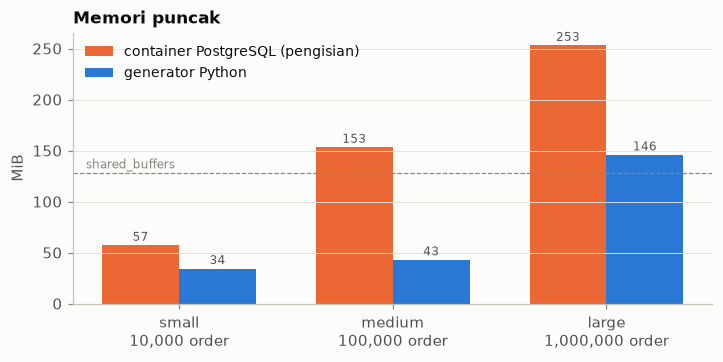


**Analisis:**
- **Container PostgreSQL:** memori puncaknya terjadi saat pengisian, yaitu 57,0 MiB, 153,1 MiB, dan 253,0 MiB pada small, medium, dan large. Pada large ini hanya 3,2% dari 7,75 GiB yang dialokasikan ke Docker. Memori proses saja (tanpa page cache) lebih kecil lagi, 69,9 MiB pada large.
- **Pertumbuhan memori:** data naik 100 kali, memori puncak container naik 4,4×. Jadi memori tumbuh jauh lebih lambat dari data. Ini sesuai dengan cara kerja `COPY`, yang memproses data baris demi baris dan menulisnya ke disk, bukan menahan seluruhnya di memori.
- **Generator Python:** memori puncaknya 34,2 MiB, 42,8 MiB, dan 145,7 MiB. Naik 4,3× untuk data yang naik 100 kali, jadi generator menulis script SQL secara bertahap dan tidak menyimpan seluruh dataset di memori.
- **CPU:** pengisian memakai rata-rata sekitar 104%–106% satu core di semua ukuran, artinya satu core penuh. Itu wajar karena satu transaksi `COPY` dijalankan oleh satu proses PostgreSQL. Puncak sesaat pada large (251%) kemungkinan berasal dari proses latar PostgreSQL (misalnya penulisan WAL dan checkpoint) yang sesekali memakai core tambahan, tetapi penyebabnya tidak diukur. Karena rata-ratanya tetap sekitar satu core, **kecepatan pengisian tampaknya dibatasi kecepatan satu core**, bukan jumlah core, sehingga menambah core kemungkinan tidak mempercepat setup.
- **Pembangkitan** hampir tidak membebani container (CPU rata-rata di bawah 5%), karena kerjanya ada di proses Python di host.
- **Catatan:** memori tahap diam (`idle`) pada large (137,3 MiB) jauh lebih besar dari pada small (21,7 MiB). Ini bukan akibat ukuran data, karena saat itu database sementara belum dibuat. Penyebab yang paling mungkin adalah kondisi container (misalnya page cache dari pengukuran sebelumnya), sehingga perbedaan di tahap ini tidak dipakai sebagai dasar kesimpulan.


In [8]:
cont = {p: S[p]['container'] for p in PROFILES}
PHASES = ['idle', 'schema', 'generate', 'load']
PHASE_LABEL = {'idle': 'diam (sebelum mulai)', 'schema': 'skema', 'generate': 'pembangkitan', 'load': 'pengisian'}

mem_rows = []
for phase in PHASES:
    row = {'tahap': PHASE_LABEL[phase]}
    for p in PROFILES:
        value = cont[p][phase]['memory_max_bytes']
        row[p] = size_text(value) if value else 'tidak ada sampel'
    mem_rows.append(row)
mem_rows.append({'tahap': 'generator Python (peak RSS)',
                 **{p: size_text(seed[p]['generator_peak_rss_bytes']) for p in PROFILES}})
say('**Memori puncak container per tahap, dan memori puncak generator Python:**')
show(pd.DataFrame(mem_rows))

cpu_rows = []
for phase in ['generate', 'load']:
    row = {'tahap': PHASE_LABEL[phase]}
    for p in PROFILES:
        c = cont[p][phase]
        row[p] = (f"rata-rata {pct_id(c['cpu_mean_percent'], 0)}, puncak {pct_id(c['cpu_max_percent'], 0)}"
                  if c['cpu_mean_percent'] is not None else 'terlalu singkat untuk diukur')
    cpu_rows.append(row)
say('**CPU container per tahap (100% = satu core penuh):**')
show(pd.DataFrame(cpu_rows))

peak = [cont[p]['load']['memory_max_bytes'] for p in PROFILES]
anon = [cont[p]['load']['anon_max_bytes'] for p in PROFILES]
rss = [seed[p]['generator_peak_rss_bytes'] for p in PROFILES]

fig, ax = plt.subplots(figsize=(7.5, 3.2))
xs = np.arange(len(PROFILES))
width = 0.36
ax.bar(xs - width / 2, [v / 2 ** 20 for v in peak], width, color=ORANGE, label='container PostgreSQL (pengisian)')
ax.bar(xs + width / 2, [v / 2 ** 20 for v in rss], width, color=BLUE, label='generator Python')
for x, a, b in zip(xs, peak, rss):
    ax.annotate(f'{a / 2 ** 20:.0f}', (x - width / 2, a / 2 ** 20), xytext=(0, 3), textcoords='offset points',
                ha='center', fontsize=8, color=INK_2)
    ax.annotate(f'{b / 2 ** 20:.0f}', (x + width / 2, b / 2 ** 20), xytext=(0, 3), textcoords='offset points',
                ha='center', fontsize=8, color=INK_2)
ax.axhline(SETTINGS_MB := int(SETTINGS['shared_buffers'].removesuffix('MB')), color=MUTED, lw=0.8, ls='--')
ax.annotate('shared_buffers', (-0.45, SETTINGS_MB), xytext=(2, 3), textcoords='offset points', fontsize=8, color=MUTED)
ax.set_xticks(xs, labels=[f'{p}\n{ORDERS[p]:,} order' for p in PROFILES])
ax.set_ylabel('MiB')
ax.grid(axis='x', visible=False)
ax.legend(loc='upper left')
ax.set_title('Memori puncak')
plt.show()

load_cpu_mean = [cont[p]['load']['cpu_mean_percent'] for p in PROFILES]
load_cpu_max = [cont[p]['load']['cpu_max_percent'] for p in PROFILES]
say(f"""
**Analisis:**
- **Container PostgreSQL:** memori puncaknya terjadi saat pengisian, yaitu {size_text(peak[0])}, {size_text(peak[1])}, dan {size_text(peak[2])} pada small, medium, dan large. Pada large ini hanya {pct_id(peak[2] / DOCKER['memory_bytes'] * 100)} dari {size_text(DOCKER['memory_bytes'])} yang dialokasikan ke Docker. Memori proses saja (tanpa page cache) lebih kecil lagi, {size_text(anon[2])} pada large.
- **Pertumbuhan memori:** data naik 100 kali, memori puncak container naik {times(peak[2] / peak[0])}. Jadi memori tumbuh jauh lebih lambat dari data. Ini sesuai dengan cara kerja `COPY`, yang memproses data baris demi baris dan menulisnya ke disk, bukan menahan seluruhnya di memori.
- **Generator Python:** memori puncaknya {size_text(rss[0])}, {size_text(rss[1])}, dan {size_text(rss[2])}. Naik {times(rss[2] / rss[0])} untuk data yang naik 100 kali, jadi generator menulis script SQL secara bertahap dan tidak menyimpan seluruh dataset di memori.
- **CPU:** pengisian memakai rata-rata sekitar {pct_id(min(load_cpu_mean), 0)}–{pct_id(max(load_cpu_mean), 0)} satu core di semua ukuran, artinya satu core penuh. Itu wajar karena satu transaksi `COPY` dijalankan oleh satu proses PostgreSQL. Puncak sesaat pada large ({pct_id(load_cpu_max[2], 0)}) kemungkinan berasal dari proses latar PostgreSQL (misalnya penulisan WAL dan checkpoint) yang sesekali memakai core tambahan, tetapi penyebabnya tidak diukur. Karena rata-ratanya tetap sekitar satu core, **kecepatan pengisian tampaknya dibatasi kecepatan satu core**, bukan jumlah core, sehingga menambah core kemungkinan tidak mempercepat setup.
- **Pembangkitan** hampir tidak membebani container (CPU rata-rata di bawah 5%), karena kerjanya ada di proses Python di host.
- **Catatan:** memori tahap diam (`idle`) pada large ({size_text(cont['large']['idle']['memory_max_bytes'])}) jauh lebih besar dari pada small ({size_text(cont['small']['idle']['memory_max_bytes'])}). Ini bukan akibat ukuran data, karena saat itu database sementara belum dibuat. Penyebab yang paling mungkin adalah kondisi container (misalnya page cache dari pengukuran sebelumnya), sehingga perbedaan di tahap ini tidak dipakai sebagai dasar kesimpulan.
""")

## 5. Pemakaian storage

Storage dibaca dari PostgreSQL setelah pengisian selesai. Ada tiga kebutuhan yang berbeda:
- **Database:** ukuran database di disk container (`pg_database_size`), yaitu tabel, indeks, dan katalog sistem.
- **Script SQL:** berkas sementara di host yang menampung hasil pembangkitan sebelum dimuat. Berkas ini dihapus setelah pengukuran.
- **WAL:** log tulis PostgreSQL yang dihasilkan selama pengisian. WAL terus dipakai ulang dan dihapus oleh PostgreSQL, jadi angkanya adalah total yang ditulis, bukan yang tersimpan.

| ukuran data | database | tabel | indeks | katalog sistem | script SQL (host) | WAL yang ditulis |
|---|---|---|---|---|---|---|
| small | 19,9 MiB | 7,2 MiB | 4,8 MiB | 7,9 MiB | 4,9 MiB | 19,9 MiB |
| medium | 106,9 MiB | 56,3 MiB | 42,8 MiB | 7,9 MiB | 48,6 MiB | 196,1 MiB |
| large | 964,5 MiB | 530,7 MiB | 425,9 MiB | 7,9 MiB | 485,5 MiB | 2,12 GiB |

| ukuran data | database per order | indeks ÷ tabel | WAL ÷ database | script ÷ database |
|---|---|---|---|---|
| small | 2,04 KiB | 67% | 1,0× | 0,2× |
| medium | 1,09 KiB | 76% | 1,8× | 0,5× |
| large | 0,99 KiB | 80% | 2,3× | 0,5× |

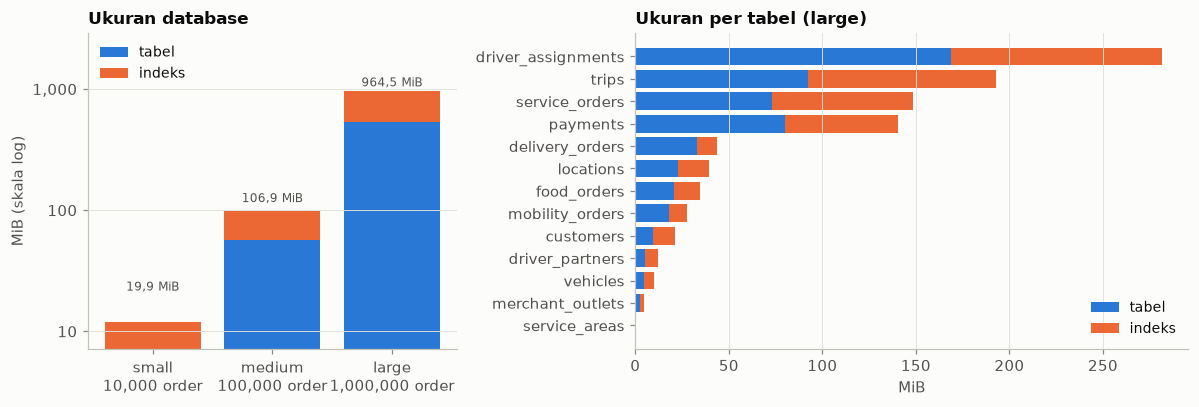


**Analisis:**
- **Ukuran database:** 19,9 MiB, 106,9 MiB, dan 964,5 MiB untuk small, medium, dan large. Kenaikannya 5,4× lalu 9,0× (b = 0,84). Jauh lebih landai di langkah pertama karena ada ukuran tetap sebesar 7,9 MiB untuk katalog sistem PostgreSQL (7,9 MiB dan 7,9 MiB pada medium dan large), yang tidak bergantung pada jumlah data. Pada data yang lebih besar ukuran tetap itu tidak berarti lagi, sehingga pertumbuhannya mendekati linier.
- **Biaya per order:** sekitar 0,99 KiB per order pada large (sudah termasuk seluruh tabel terkait order seperti pembayaran, penugasan driver, dan trip).
- **Indeks:** ukurannya setara 80% dari ukuran tabel pada large. driver_partners memiliki rasio indeks terhadap tabel tertinggi (132%, 3 indeks). Indeks perlu dihitung dalam kapasitas disk, bukan hanya datanya.
- **Tabel terbesar:** driver_assignments, trips dan service_orders memakai 65% dari seluruh tabel dan indeks pada large. Tabel-tabel yang paling besar ini juga yang paling mungkin berpengaruh pada waktu query di volume test.
- **WAL:** WAL yang ditulis sekitar 2,3× ukuran database pada large (2,12 GiB), dan rasionya naik dari 1,0× pada small. Nilainya melebihi `max_wal_size` (1GB) pada large, sehingga PostgreSQL kemungkinan memicu checkpoint tambahan di tengah pengisian. Dampaknya ke waktu pengisian tidak diukur. Pada small (19,9 MiB) dan medium (196,1 MiB), WAL masih di bawah batas itu.
- **Script SQL:** berkas sementara di host berukuran 485,5 MiB pada large, sekitar setengah ukuran database. Ia perlu ruang disk tambahan di host selama setup.


In [9]:
st = {p: S[p]['storage'] for p in PROFILES}
db = [st[p]['database_bytes'] for p in PROFILES]
tbl = [sum(t['table_bytes'] for t in st[p]['tables']) for p in PROFILES]
idx = [sum(t['index_bytes'] for t in st[p]['tables']) for p in PROFILES]
overhead = [d - a - b for d, a, b in zip(db, tbl, idx)]
script = [seed[p]['script_bytes'] for p in PROFILES]
wal = [seed[p]['wal_bytes'] for p in PROFILES]

show(pd.DataFrame({
    'ukuran data': PROFILES,
    'database': [size_text(v) for v in db],
    'tabel': [size_text(v) for v in tbl],
    'indeks': [size_text(v) for v in idx],
    'katalog sistem': [size_text(v) for v in overhead],
    'script SQL (host)': [size_text(v) for v in script],
    'WAL yang ditulis': [size_text(v) for v in wal],
}))

show(pd.DataFrame({
    'ukuran data': PROFILES,
    'database per order': [dec(d / ORDERS[p] / 1024, 2) + ' KiB' for d, p in zip(db, PROFILES)],
    'indeks ÷ tabel': [pct_id(i / t * 100, 0) for i, t in zip(idx, tbl)],
    'WAL ÷ database': [times(w / d) for w, d in zip(wal, db)],
    'script ÷ database': [times(s / d) for s, d in zip(script, db)],
}))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={'width_ratios': [1, 1.5]})
ax = axes[0]
xs = np.arange(len(PROFILES))
ax.bar(xs, [v / 2 ** 20 for v in tbl], color=BLUE, label='tabel')
ax.bar(xs, [v / 2 ** 20 for v in idx], bottom=[v / 2 ** 20 for v in tbl], color=ORANGE, label='indeks')
for x, d in zip(xs, db):
    ax.annotate(size_text(d), (x, d / 2 ** 20), xytext=(0, 3), textcoords='offset points', ha='center', fontsize=8,
                color=INK_2)
ax.set_yscale('log')
ax.minorticks_off()
ax.yaxis.set_major_formatter(PLAIN)
ax.set_ylim(top=max(db) / 2 ** 20 * 3)
ax.set_xticks(xs, labels=[f'{p}\n{ORDERS[p]:,} order' for p in PROFILES])
ax.set_ylabel('MiB (skala log)')
ax.grid(axis='x', visible=False)
ax.legend(loc='upper left')
ax.set_title('Ukuran database')

ax = axes[1]
large_tables = sorted(st['large']['tables'], key=lambda t: t['table_bytes'] + t['index_bytes'])
ys = np.arange(len(large_tables))
ax.barh(ys, [t['table_bytes'] / 2 ** 20 for t in large_tables], color=BLUE, label='tabel')
ax.barh(ys, [t['index_bytes'] / 2 ** 20 for t in large_tables], left=[t['table_bytes'] / 2 ** 20 for t in large_tables],
        color=ORANGE, label='indeks')
ax.set_yticks(ys, labels=[t['table'] for t in large_tables])
ax.set_xlabel('MiB')
ax.grid(axis='y', visible=False)
ax.legend(loc='lower right')
ax.set_title('Ukuran per tabel (large)')
plt.tight_layout()
plt.show()

per_table = sorted(st['large']['tables'], key=lambda t: t['table_bytes'] + t['index_bytes'], reverse=True)
top3 = per_table[:3]
top3_share = sum(t['table_bytes'] + t['index_bytes'] for t in top3) / (tbl[2] + idx[2]) * 100
idx_heavy = max((t for t in per_table if t['table_bytes'] > 2 ** 20), key=lambda t: t['index_bytes'] / t['table_bytes'])
say(f"""
**Analisis:**
- **Ukuran database:** {size_text(db[0])}, {size_text(db[1])}, dan {size_text(db[2])} untuk small, medium, dan large. Kenaikannya {times(growth(db)[0])} lalu {times(growth(db)[1])} (b = {dec(loglog_slope(db), 2)}). Jauh lebih landai di langkah pertama karena ada ukuran tetap sebesar {size_text(overhead[0])} untuk katalog sistem PostgreSQL ({size_text(overhead[1])} dan {size_text(overhead[2])} pada medium dan large), yang tidak bergantung pada jumlah data. Pada data yang lebih besar ukuran tetap itu tidak berarti lagi, sehingga pertumbuhannya mendekati linier.
- **Biaya per order:** sekitar {dec(db[2] / ORDERS['large'] / 1024, 2)} KiB per order pada large (sudah termasuk seluruh tabel terkait order seperti pembayaran, penugasan driver, dan trip).
- **Indeks:** ukurannya setara {pct_id(idx[2] / tbl[2] * 100, 0)} dari ukuran tabel pada large. {idx_heavy['table']} memiliki rasio indeks terhadap tabel tertinggi ({pct_id(idx_heavy['index_bytes'] / idx_heavy['table_bytes'] * 100, 0)}, {idx_heavy['indexes']} indeks). Indeks perlu dihitung dalam kapasitas disk, bukan hanya datanya.
- **Tabel terbesar:** {names([t['table'] for t in top3])} memakai {pct_id(top3_share, 0)} dari seluruh tabel dan indeks pada large. Tabel-tabel yang paling besar ini juga yang paling mungkin berpengaruh pada waktu query di volume test.
- **WAL:** WAL yang ditulis sekitar {times(wal[2] / db[2])} ukuran database pada large ({size_text(wal[2])}), dan rasionya naik dari {times(wal[0] / db[0])} pada small. Nilainya {'melebihi' if wal[2] > 2 ** 30 else 'di bawah'} `max_wal_size` ({SETTINGS['max_wal_size']}) pada large, sehingga PostgreSQL kemungkinan memicu checkpoint tambahan di tengah pengisian. Dampaknya ke waktu pengisian tidak diukur. Pada small ({size_text(wal[0])}) dan medium ({size_text(wal[1])}), WAL masih di bawah batas itu.
- **Script SQL:** berkas sementara di host berukuran {size_text(script[2])} pada large, sekitar setengah ukuran database. Ia perlu ruang disk tambahan di host selama setup.
""")

## 6. Kelayakan: mesin seperti apa yang cukup?

Bagian ini merangkum bagian 3–5 menjadi kebutuhan per ukuran data, lalu membandingkannya dengan mesin yang dipakai. Kebutuhan di sini adalah **yang terukur saat setup**, bukan saat query dijalankan. Untuk query, memori dan cache yang dibutuhkan bisa berbeda.

In [10]:
need_mem = [max(cont[p][ph]['memory_max_bytes'] or 0 for ph in PHASES) for p in PROFILES]
need_disk_db = db
need_disk_host = [s + d for s, d in zip(script, db)]
ECS = {'GB': 2 ** 30, 'MB': 2 ** 20}[SETTINGS['effective_cache_size'][-2:]] * int(SETTINGS['effective_cache_size'][:-2])

show(pd.DataFrame({
    'ukuran data': PROFILES,
    'waktu setup': [sec_text(t + schema_secs[i]) for i, t in enumerate(total)],
    'memori container (puncak)': [size_text(v) for v in need_mem],
    'memori generator (puncak)': [size_text(v) for v in rss],
    'disk database': [size_text(v) for v in db],
    'disk sementara (script + database)': [size_text(v) for v in need_disk_host],
    'kebutuhan CPU': ['1 core'] * len(PROFILES),
}))

show(pd.DataFrame({
    'ukuran data': PROFILES,
    'memori container ÷ alokasi Docker': [pct_id(v / DOCKER['memory_bytes'] * 100) for v in need_mem],
    'database ÷ shared_buffers': [times(d / (int(SETTINGS['shared_buffers'].removesuffix('MB')) * 2 ** 20)) for d in db],
    'database ÷ effective_cache_size': [pct_id(d / ECS * 100, 0) for d in db],
    'disk sementara ÷ disk host': [pct_id(v / HOST['disk_bytes'] * 100, 2) for v in need_disk_host],
}))

ECS = {'GB': 2 ** 30, 'MB': 2 ** 20}[SETTINGS['effective_cache_size'][-2:]] * int(SETTINGS['effective_cache_size'][:-2])
fits_mem = need_mem[2] < DOCKER['memory_bytes']
fits_disk = need_disk_host[2] < HOST['disk_bytes']
say(f"""
**Analisis:**
- **Mesin ini lebih dari cukup untuk ketiganya.** Pada large, setup butuh {size_text(need_mem[2])} memori container, {size_text(need_disk_host[2])} disk sementara, dan satu core, sedangkan yang tersedia {size_text(DOCKER['memory_bytes'])} memori Docker, {size_text(HOST['disk_bytes'])} disk, dan {DOCKER['cpus']} core. Pemakaiannya {pct_id(need_mem[2] / DOCKER['memory_bytes'] * 100)} dari memori Docker dan {pct_id(need_disk_host[2] / HOST['disk_bytes'] * 100, 2)} dari disk.
- **Batas bawah yang masuk akal:** karena memori tumbuh jauh lebih lambat dari data (bagian 4), setup tidak menuntut RAM besar. Mesin dengan memori Docker 1–2 GiB, beberapa GiB disk kosong, dan satu core yang tidak terlalu lambat seharusnya sudah bisa menjalankan large, hanya dengan waktu lebih lama. Angka ini adalah **perkiraan dari ekstrapolasi, bukan hasil pengukuran** di mesin yang lebih kecil, karena semua pengukuran dilakukan di satu mesin.
- **Yang menentukan waktu adalah kecepatan satu core.** Karena pengisian memakai satu core ({pct_id(min(load_cpu_mean), 0)}–{pct_id(max(load_cpu_mean), 0)}), waktu large di mesin yang core-nya lebih lambat akan memanjang secara proporsional, sedangkan jumlah core tidak berpengaruh.
- **Database tidak muat di `shared_buffers`:** pada large, ukuran database {times(db[2] / (int(SETTINGS['shared_buffers'].removesuffix('MB')) * 2 ** 20))} lebih besar dari `shared_buffers` ({SETTINGS['shared_buffers']}), tetapi {pct_id(db[2] / ECS * 100, 0)} dari `effective_cache_size` ({SETTINGS['effective_cache_size']}). Dengan konfigurasi bawaan, sebagian besar data large akan dibaca lewat cache sistem operasi, bukan buffer PostgreSQL. Ini relevan untuk membaca hasil volume test pada large, tetapi di luar cakupan pengukuran setup.
- **Pengisian ulang:** small dan medium dapat diisi ulang kapan saja (kurang dari satu menit). Large memerlukan beberapa menit, sehingga sebaiknya dibuat sekali dan dipakai ulang.
""")

| ukuran data | waktu setup | memori container (puncak) | memori generator (puncak) | disk database | disk sementara (script + database) | kebutuhan CPU |
|---|---|---|---|---|---|---|
| small | 2,53 detik | 57,0 MiB | 34,2 MiB | 19,9 MiB | 24,8 MiB | 1 core |
| medium | 20,7 detik | 153,1 MiB | 42,8 MiB | 106,9 MiB | 155,5 MiB | 1 core |
| large | 3 menit 46 detik | 253,0 MiB | 145,7 MiB | 964,5 MiB | 1,42 GiB | 1 core |

| ukuran data | memori container ÷ alokasi Docker | database ÷ shared_buffers | database ÷ effective_cache_size | disk sementara ÷ disk host |
|---|---|---|---|---|
| small | 0,7% | 0,2× | 0% | 0,00% |
| medium | 1,9% | 0,8× | 3% | 0,02% |
| large | 3,2% | 7,5× | 24% | 0,15% |


**Analisis:**
- **Mesin ini lebih dari cukup untuk ketiganya.** Pada large, setup butuh 253,0 MiB memori container, 1,42 GiB disk sementara, dan satu core, sedangkan yang tersedia 7,75 GiB memori Docker, 926,30 GiB disk, dan 10 core. Pemakaiannya 3,2% dari memori Docker dan 0,15% dari disk.
- **Batas bawah yang masuk akal:** karena memori tumbuh jauh lebih lambat dari data (bagian 4), setup tidak menuntut RAM besar. Mesin dengan memori Docker 1–2 GiB, beberapa GiB disk kosong, dan satu core yang tidak terlalu lambat seharusnya sudah bisa menjalankan large, hanya dengan waktu lebih lama. Angka ini adalah **perkiraan dari ekstrapolasi, bukan hasil pengukuran** di mesin yang lebih kecil, karena semua pengukuran dilakukan di satu mesin.
- **Yang menentukan waktu adalah kecepatan satu core.** Karena pengisian memakai satu core (104%–106%), waktu large di mesin yang core-nya lebih lambat akan memanjang secara proporsional, sedangkan jumlah core tidak berpengaruh.
- **Database tidak muat di `shared_buffers`:** pada large, ukuran database 7,5× lebih besar dari `shared_buffers` (128MB), tetapi 24% dari `effective_cache_size` (4GB). Dengan konfigurasi bawaan, sebagian besar data large akan dibaca lewat cache sistem operasi, bukan buffer PostgreSQL. Ini relevan untuk membaca hasil volume test pada large, tetapi di luar cakupan pengukuran setup.
- **Pengisian ulang:** small dan medium dapat diisi ulang kapan saja (kurang dari satu menit). Large memerlukan beberapa menit, sehingga sebaiknya dibuat sekali dan dipakai ulang.


## 7. Kesimpulan

In [11]:
say(f"""
1. **Setup layak dijalankan di laptop modern.** Pada mesin uji ({HOST['cpu']}, {DOCKER['cpus']} core dan {size_text(DOCKER['memory_bytes'])} untuk Docker), ketiga ukuran data berhasil dibuat tanpa kegagalan. Large (1 juta order, {count_id(rows_total[2])} baris) selesai dalam {sec_text(total[2] + schema_secs[2])} dan memakai {size_text(db[2])} untuk database.
2. **Waktu tumbuh hampir linier terhadap data.** Pembangkitan dan pengisian masing-masing naik sekitar 10 kali setiap data naik 10 kali (b = {dec(b_gen, 2)} dan {dec(b_load, 2)}). Pembuatan skema ({dec(min(schema_secs), 2)}–{dec(max(schema_secs), 2)} detik) tidak bergantung pada data.
3. **Memori bukan kendala.** Memori puncak container hanya {size_text(peak[2])} pada large ({pct_id(peak[2] / DOCKER['memory_bytes'] * 100)} dari alokasi Docker), dan memori generator {size_text(rss[2])}. Keduanya tumbuh jauh lebih lambat dari data.
4. **Kendala utamanya CPU satu core dan waktu tunggu.** Pengisian rata-rata memakai satu core penuh, sehingga mesin dengan lebih banyak core kemungkinan tidak lebih cepat. Biaya terbesarnya ada di pengisian ({pct_id(share_load[2], 0)} dari total waktu pada large) karena {objects['indexes']} indeks, {objects['foreign_keys']} foreign key, dan {objects['triggers']} trigger aktif selama `COPY`.
5. **Storage tumbuh linier, dan indeks bukan hal kecil.** Database large {size_text(db[2])}, sekitar {dec(db[2] / ORDERS['large'] / 1024, 2)} KiB per order. Indeks setara {pct_id(idx[2] / tbl[2] * 100, 0)} dari ukuran tabel. Selama pengisian large, WAL {size_text(wal[2])} dan script SQL sementara {size_text(script[2])} ikut menggunakan disk.
6. **Konfigurasi bawaan PostgreSQL cukup untuk setup, tetapi WAL large melampaui `max_wal_size`.** Menaikkan `max_wal_size` kemungkinan mempercepat pengisian large. Ini dugaan dari angka di atas dan belum diuji.
7. **Batasan:** satu pengukuran per ukuran data, satu mesin, satu konfigurasi, tanpa pengulangan. Angka di notebook ini menunjukkan orde besarnya, bukan nilai yang pasti, dan kebutuhan minimum di mesin yang lebih kecil belum diukur langsung.
""")


1. **Setup layak dijalankan di laptop modern.** Pada mesin uji (Apple M5, 10 core dan 7,75 GiB untuk Docker), ketiga ukuran data berhasil dibuat tanpa kegagalan. Large (1 juta order, 6.021.440 baris) selesai dalam 3 menit 46 detik dan memakai 964,5 MiB untuk database.
2. **Waktu tumbuh hampir linier terhadap data.** Pembangkitan dan pengisian masing-masing naik sekitar 10 kali setiap data naik 10 kali (b = 0,98 dan 1,00). Pembuatan skema (0,17–0,31 detik) tidak bergantung pada data.
3. **Memori bukan kendala.** Memori puncak container hanya 253,0 MiB pada large (3,2% dari alokasi Docker), dan memori generator 145,7 MiB. Keduanya tumbuh jauh lebih lambat dari data.
4. **Kendala utamanya CPU satu core dan waktu tunggu.** Pengisian rata-rata memakai satu core penuh, sehingga mesin dengan lebih banyak core kemungkinan tidak lebih cepat. Biaya terbesarnya ada di pengisian (82% dari total waktu pada large) karena 34 indeks, 14 foreign key, dan 21 trigger aktif selama `COPY`.
5. **Storage tumbuh linier, dan indeks bukan hal kecil.** Database large 964,5 MiB, sekitar 0,99 KiB per order. Indeks setara 80% dari ukuran tabel. Selama pengisian large, WAL 2,12 GiB dan script SQL sementara 485,5 MiB ikut menggunakan disk.
6. **Konfigurasi bawaan PostgreSQL cukup untuk setup, tetapi WAL large melampaui `max_wal_size`.** Menaikkan `max_wal_size` kemungkinan mempercepat pengisian large. Ini dugaan dari angka di atas dan belum diuji.
7. **Batasan:** satu pengukuran per ukuran data, satu mesin, satu konfigurasi, tanpa pengulangan. Angka di notebook ini menunjukkan orde besarnya, bukan nilai yang pasti, dan kebutuhan minimum di mesin yang lebih kecil belum diukur langsung.
